In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, chebwin, freqz, lfilter

# ==========================================
# Chapter 5 Common Helper Functions
# ==========================================
def make_bank_DFT(p: np.ndarray, N: int):
    """Generate DFT Filter Bank with N subbands."""
    p = p.flatten()
    flen = len(p)
    H = np.zeros((flen, N // 2 + 1), dtype=complex)
    n = np.arange(flen)
    H[:, 0] = p
    H[:, N // 2] = p * ((-1)**n)
    for k in range(1, N // 2):
        H[:, k] = p * np.exp(1j * 2 * np.pi / N * k * n)
    D = H[:, 1 : N // 2]
    H_full = np.hstack((H, np.conj(np.fliplr(D))))
    F_full = H_full
    return H_full.T, F_full.T # Returns (N, L) shape

def make_bank_3(h: np.ndarray, nbands: int):
    """Cosine modulation with phase reference (L-1)/2."""
    flen = len(h)
    H = np.zeros((nbands, flen))
    n = np.arange(flen)
    for k in range(1, nbands + 1):
        H[k - 1, :] = h * np.cos((np.pi / nbands) * (k - 0.5) * (n - (flen - 1) / 2.0) + 
                                 (np.pi / 2.0) * (k + 0.5) * (flen - 1 - nbands) / nbands) * 2
    G = np.fliplr(H)
    return H, G

def FreqResp(H: np.ndarray, DFTpoint: int = 4096):
    """Computes frequency response over [0, pi] or [0, 2pi]."""
    if H.ndim == 1:
        H = H.reshape(1, -1)
    N, L = H.shape
    Hz = np.zeros((N, DFTpoint), dtype=complex)
    for k in range(N):
        Hz[k, :] = np.fft.fft(H[k, :], 2 * DFTpoint)[:DFTpoint]
    w = np.linspace(0, np.pi, DFTpoint)
    return Hz, w

def dist_alias(H: np.ndarray, G: np.ndarray, nband: int):
    """Python translation of dist_alias.m (Calculates Amplitude Distortion & Aliasing)."""
    N = H.shape[1]
    A = np.zeros((nband, 2 * N - 1), dtype=complex)
    n_idx = np.arange(N)
    
    for m in range(nband):
        for k in range(nband):
            mod_H = H[k, :] * np.exp(-1j * n_idx * 2 * np.pi * m / nband)
            A[m, :] += np.convolve(mod_H, G[k, :])
            
    A0 = np.zeros(1024)
    for m in range(1, nband):
        A0 += (np.abs(np.fft.fft(A[m, :], 1024)) / nband)**2
    A0 = np.sqrt(A0)
    
    DFTpoint = 4096
    h, w = FreqResp(A[0, :], DFTpoint)
    
    # Plotting
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.plot(w / np.pi, 10 * np.log10(np.abs(h.squeeze()) + 1e-12))
    plt.title('Distortion Plot')
    plt.xlabel(r'Frequency, $\omega (\pi)$'); plt.ylabel('Amplitude distortion (dB)')
    plt.xlim([0, 1]); plt.grid(True)
    
    plt.subplot(2, 1, 2)
    w_alias = np.linspace(0, 1, 513)
    plt.plot(w_alias, A0[:513])
    plt.title('Total Aliasing Distortion')
    plt.xlabel(r'Frequency, $\omega (\pi)$'); plt.ylabel('Aliasing error')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

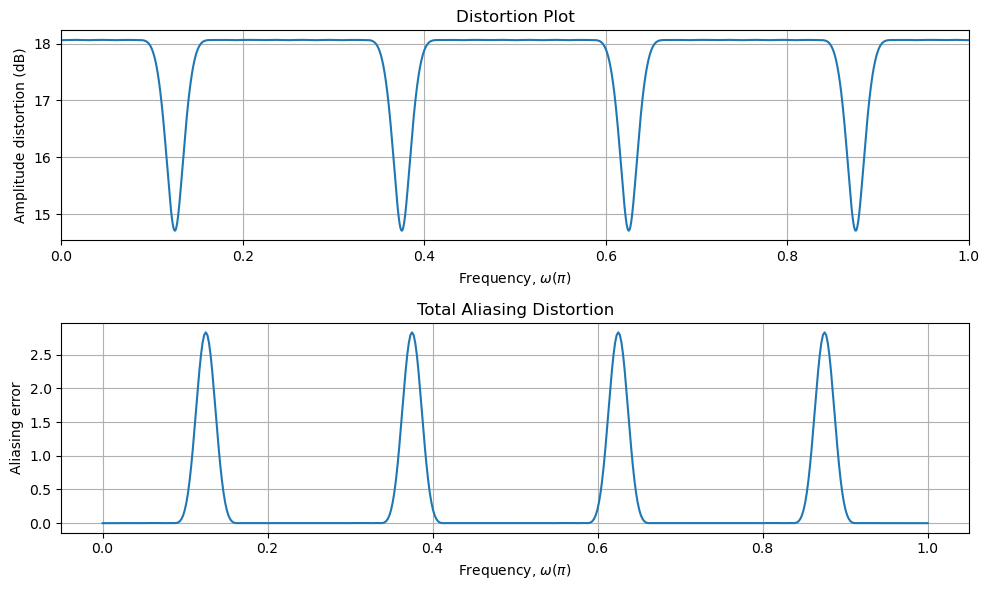

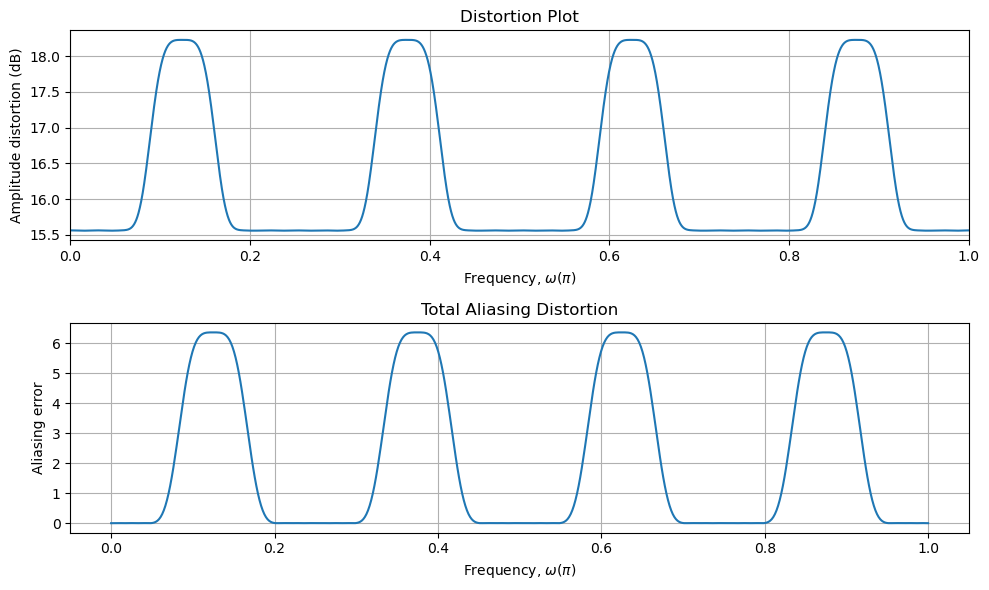

In [3]:
# ==========================================
# Example 5.1 Execution
# ==========================================
Fs = 8000; Rs = 60; L = 127
nbands = 8; NFFT = 1024

# 1. Critically-Sampled Case (D = 8)
wc_crit = 1.0 / 8.0
b_crit = firwin(L + 1, wc_crit, window=('chebwin', Rs), fs=2.0)
H_c, G_c = make_bank_DFT(b_crit, nbands)
H_c *= np.sqrt(8); G_c *= np.sqrt(8)

dist_alias(H_c, G_c, nbands)

# 2. Oversampled Case (D = 6)
wc_over = 1.0 / 6.0
b_over = firwin(L + 1, wc_over, window=('chebwin', Rs), fs=2.0)
H_o, G_o = make_bank_DFT(b_over, nbands)
H_o *= np.sqrt(6); G_o *= np.sqrt(6)

dist_alias(H_o, G_o, nbands)

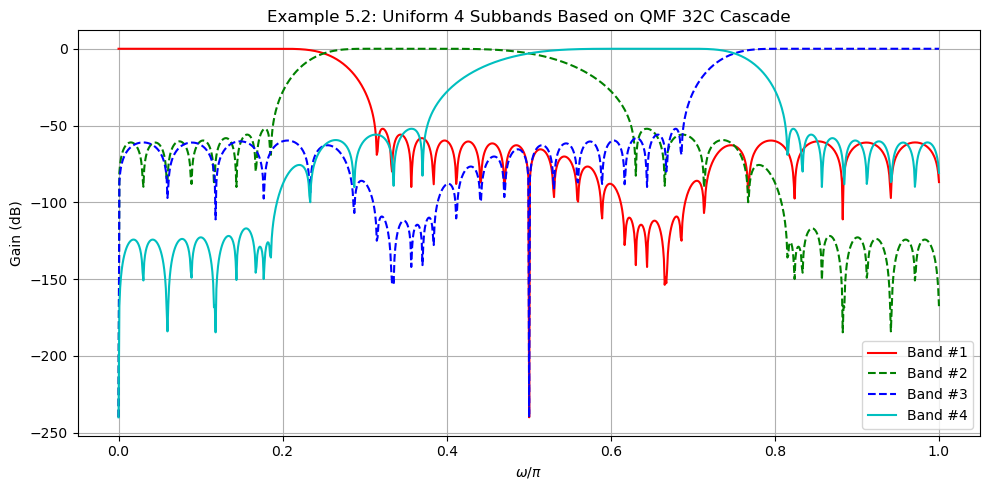

In [4]:
# ==========================================
# Example 5.2 Execution
# ==========================================
h0_32C_half = np.array([.69105790e-3, -0.14037930e-2, -0.12683030e-2, .4234195e-2, 
                        .1414246e-2, -0.9458318e-2, -0.1303859e-3, .1798145e-1, 
                        -0.4187483e-2, -0.3123862e-1, .1456844e-1, .5294745e-1, 
                        -0.3934878e-1, -0.9980243e-1, .1285579, .46640530])

h0_32C = np.concatenate((h0_32C_half, h0_32C_half[::-1]))
h1_32C = ((-1.0)**np.arange(len(h0_32C))) * h0_32C

B1 = h0_32C; B2 = h1_32C
B10 = np.zeros(2 * len(B1)); B10[::2] = B1
B11 = np.zeros(2 * len(B2)); B11[::2] = B2

C0 = np.convolve(B1, B10); C1 = np.convolve(B1, B11)
C2 = np.convolve(B2, B10); C3 = np.convolve(B2, B11)

N_pts = 1024
w_qmf = np.linspace(0, 1, N_pts)

plt.figure(figsize=(10, 5))
for C_filt, label_str, style_str in zip([C0, C1, C2, C3], 
                                         ['Band #1', 'Band #2', 'Band #3', 'Band #4'], 
                                         ['r-', 'g--', 'b--', 'c-']):
    _, H_z = freqz(C_filt, 1, N_pts)
    plt.plot(w_qmf, 20 * np.log10(np.abs(H_z) + 1e-12), style_str, label=label_str, linewidth=1.5)

plt.title('Example 5.2: Uniform 4 Subbands Based on QMF 32C Cascade')
plt.xlabel(r'$\omega / \pi$'); plt.ylabel('Gain (dB)')
plt.grid(True); plt.legend(loc='best'); plt.tight_layout()
plt.show()

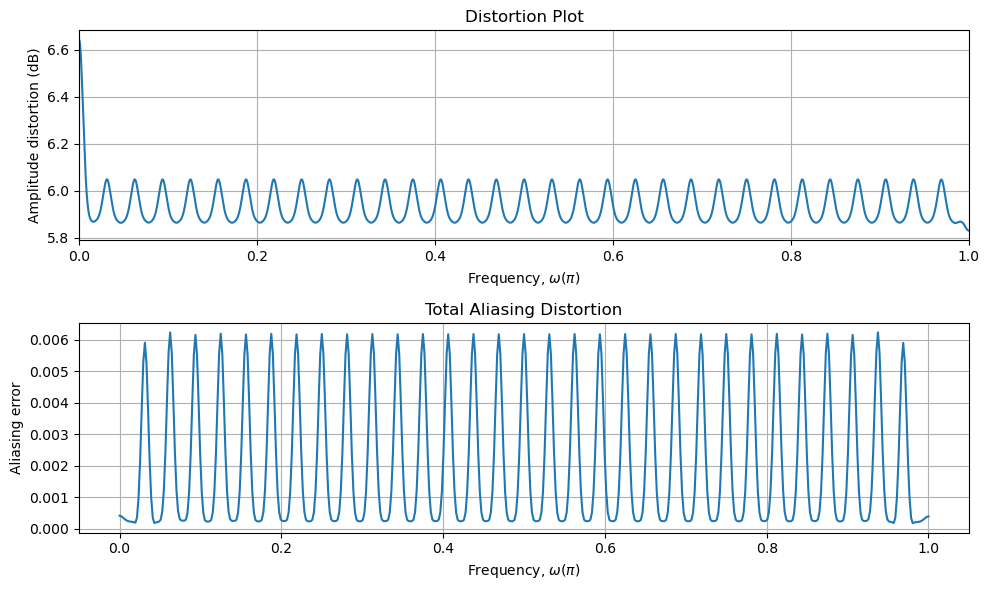

In [5]:
# ==========================================
# Example 5.3 Execution
# ==========================================
C = np.array([
    0.0, -0.000000477, -0.000000477, -0.000000477, -0.000000477, -0.000000477, -0.000000477, -0.000000954,
    -0.000000954, -0.000000954, -0.000000954, -0.000001431, -0.000001431, -0.000001907, -0.000001907, -0.000002384,
    -0.000002384, -0.000002861, -0.000003338, -0.000003338, -0.000003815, -0.000004292, -0.000004768, -0.000005245,
    -0.000006199, -0.000006676, -0.000007629, -0.000008106, -0.000009060, -0.000010014, -0.000011444, -0.000012398,
    -0.000013828, -0.000014782, -0.000016689, -0.000018120, -0.000019550, -0.000021458, -0.000023365, -0.000025272,
    -0.000027657, -0.000030041, -0.000032425, -0.000034809, -0.000037670, -0.000040531, -0.000043392, -0.000046253,
    -0.000049591, -0.000052929, -0.000055790, -0.000059605, -0.000062943, -0.000066280, -0.000070095, -0.000073433,
    -0.000076771, -0.000080585, -0.000083923, -0.000087261, -0.000090599, -0.000093460, -0.000096321, -0.000099182,
    -0.000101566, -0.000103951, -0.000105858, -0.000107288, -0.000108242, -0.000108719, -0.000108719, -0.000108242,
    -0.000106812, -0.000105381, -0.000102520, -0.000099182, -0.000095367, -0.000090122, -0.000084400, -0.000077724,
    -0.000069618, -0.000060558, -0.000050545, -0.000039577, -0.000027180, -0.000013828,  0.000000954,  0.000017166,
     0.000034332,  0.000052929,  0.000072956,  0.000093937,  0.000116348,  0.000140190,  0.000165462,  0.000191212,
     0.000218868,  0.000247478,  0.000277042,  0.000307560,  0.000339031,  0.000371456,  0.000404358,  0.000438213,
     0.000472546,  0.000507355,  0.000542164,  0.000576973,  0.000611782,  0.000646591,  0.000680923,  0.000714302,
     0.000747204,  0.000779152,  0.000809669,  0.000838757,  0.000866413,  0.000891685,  0.000915051,  0.000935555,
     0.000954151,  0.000968933,  0.000980854,  0.000989437,  0.000994205,  0.000995159,  0.000991821,  0.000983715,
     0.000971317,  0.000953674,  0.000930786,  0.000902653,  0.000868797,  0.000829220,  0.000783920,  0.000731945,
     0.000674248,  0.000610352,  0.000539303,  0.000462532,  0.000378609,  0.000288486,  0.000191689,  0.000088215,
    -0.000021458, -0.000137329, -0.000259876, -0.000388145, -0.000522137, -0.000661850, -0.000806808, -0.000956535,
    -0.001111031, -0.001269817, -0.001432419, -0.001597881, -0.001766682, -0.001937389, -0.002110004, -0.002283096,
    -0.002457142, -0.002630711, -0.002803326, -0.002974033, -0.003141880, -0.003306866, -0.003467083, -0.003622532,
    -0.003771782, -0.003914356, -0.004048824, -0.004174709, -0.004290581, -0.004395962, -0.004489899, -0.004570484,
    -0.004638195, -0.004691124, -0.004728317, -0.004748821, -0.004752159, -0.004737377, -0.004703045, -0.004649162,
    -0.004573822, -0.004477024, -0.004357815, -0.004215240, -0.004049301, -0.003858566, -0.003643036, -0.003401756,
    -0.003134727, -0.002841473, -0.002521515, -0.002174854, -0.001800537, -0.001399517, -0.000971317, -0.000515938,
    -0.000033379,  0.000475883,  0.001011848,  0.001573563,  0.002161503,  0.002774239,  0.003411293,  0.004072189,
     0.004756451,  0.005462170,  0.006189346,  0.006937027,  0.007703304,  0.008487225,  0.009287834,  0.010103703,
     0.010933399,  0.011775017,  0.012627602,  0.013489246,  0.014358521,  0.015233517,  0.016112804,  0.016994476,
     0.017876148,  0.018756866,  0.019634247,  0.020506859,  0.021372318,  0.022228718,  0.023074150,  0.023907185,
     0.024725437,  0.025527000,  0.026310921,  0.027073860,  0.027815342,  0.028532982,  0.029224873,  0.029890060,
     0.030526638,  0.031132698,  0.031706810,  0.032248020,  0.032754898,  0.033225536,  0.033659935,  0.034055710,
     0.034412861,  0.034730434,  0.035007000,  0.035242081,  0.035435200,  0.035586357,  0.035694122,  0.035758972,
     0.035780907
])

h_mpeg = np.concatenate((C, C[254::-1])) # Symmetric 512-tap prototype
nbands_mpeg = 32

H_mpeg, G_mpeg = make_bank_3(h_mpeg, nbands_mpeg)
dist_alias(H_mpeg, G_mpeg, nbands_mpeg)